# Torneio de desenvolvimento: qual configuração congelar?

Este notebook analisa resultados congelados em `outputs/frozen/` para identificar qual configuração do OR-Tools (Perron & Furnon, 2026) deve ser selecionada exclusivamente nas 14 instâncias de desenvolvimento sob regra pré-registrada, sem acionar nenhum solver nesta etapa.

O protocolo pré-registrado em `reports/protocolo-grade-dev.md` (Nosek et al., 2018) especificou 18 combinações resultantes do cruzamento de 2 estratégias de frota (`fixed_cost`, que resolve o problema em uma única etapa com custo fixo por veículo, e `reduce_fleet`, que itera reduzindo a frota), 3 heurísticas de construção inicial (`PARALLEL_CHEAPEST_INSERTION`, `PATH_CHEAPEST_ARC` e `SAVINGS`; Clarke & Wright, 1964) e 3 metaheurísticas (`GUIDED_LOCAL_SEARCH` de Voudouris & Tsang, 1999; `TABU_SEARCH` de Glover, 1986; e `SIMULATED_ANNEALING` de Kirkpatrick et al., 1983; visão geral em Bräysy & Gendreau, 2005b). Cada célula rodou nas 14 instâncias de desenvolvimento com orçamento de 30 s de relógio em réplica única (Barr et al., 1995).

Pela regra de seleção, as 18 configurações são ordenadas em cada instância por factibilidade, menor número de veículos e menor distância, vencendo aquela com menor posição média. Eventuais empates são decididos primeiro pelo menor Δ médio de veículos e depois pela menor mediana do gap de distância entre as instâncias com frota igual à da referência. A configuração vencedora é congelada em `outputs/frozen/selected_config.json` e segue isoladamente para a avaliação nas 42 instâncias restantes.

Para evitar vazamento metodológico (Kaufman et al., 2012), o protocolo precedeu todas as execuções, leu apenas instâncias `dev` por meio de carregadores que recusam casos de avaliação e consome cópias congeladas. A seção 9 documenta os diagnósticos posteriores da v2 (Fase B, `reports/protocolo-v2.md`), conduzidos também apenas sobre o conjunto de desenvolvimento para auditar o comportamento do solver sem alterar a seleção do torneio.

## 1. Preparação do ambiente

Nesta etapa carregam-se as instâncias de desenvolvimento, a grade congelada, o ranking consolidado e o arquivo da configuração selecionada. A tabela exibe a configuração vencedora e os indicadores que definiram o primeiro lugar.

In [1]:
LANG = "pt"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import analysis, benchmark, eda, paths, results, v2_view, viz_results
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
instances, sintef = results.load_dev_instances(P["sintef_zip"], P["sintef_bks"], split)
grid = results.load_dev_grid(R["dev_grid"], split)
ranking = results.load_ranking(R["ranking"])
selected = results.load_selected_config(R["selected_config"], split)
config = selected["config"]

display(eda.localize_columns(analysis.selected_config_table(selected, LANG), LANG))

,Indicador,Valor
0,Estratégia de frota,fixed_cost
1,Solução inicial,SAVINGS
2,Metaheurística,GUIDED_LOCAL_SEARCH
3,Posição média,5.607
4,Δ veículos médio,0.857
5,Instâncias com frota igual à referência,5
6,"Gap mediano, frota igual (%)",1.529
7,Tempo médio (s),30.0
8,Nº de instâncias,14


### Insight

A configuração selecionada combina `fixed_cost`, `SAVINGS` e `GUIDED_LOCAL_SEARCH`, obtendo posição média 5,607 nas 14 instâncias, Δ médio de 0,857 veículo, frota igual à do SINTEF em 5 casos, mediana do gap de distância de 1,529% nessas 5 instâncias e tempo médio igual ao limite de 30,0 s. Embora `selected_config.json` documente o vencedor segundo a regra pré-registrada, o arquivo isolado nada informa sobre estabilidade ou limitações da busca, aspectos verificados a seguir começando pela completude da grade.

## 2. Cobertura e factibilidade da grade

Para atestar que o torneio cobriu integralmente o desenho experimental, a tabela contabiliza a partir do arquivo congelado o total de células, os subconjuntos do torneio e de referência (construções do OR-Tools sem metaheurística e baselines próprias), eventuais vazamentos do conjunto de avaliação e a factibilidade verificada em precisão dupla.

In [2]:
display(eda.localize_columns(analysis.grid_coverage(grid, split, LANG), LANG))

,Indicador,Valor
0,Células na grade (total),322
1,Células do torneio (configurações × instâncias),252
2,Células de referência: construção do OR-Tools ...,42
3,Células de referência: heurísticas construtiva...,28
4,Configurações distintas no torneio,18
5,Instâncias distintas,14
6,Instâncias fora do conjunto de desenvolvimento,0
7,Células factíveis no verificador,322
8,Células com status parcial do solver,42
9,"Das quais, construção sem busca local",42


### Insight

A grade contém exatamente 322 células: 252 do torneio (18 configurações vezes 14 instâncias), 42 construções do OR-Tools sem busca local (3 vezes 14) e 28 das baselines construtivas (2 vezes 14), restritas às 14 instâncias de desenvolvimento. Todas as 322 soluções são factíveis em precisão dupla, garantindo que nenhuma configuração sofreu penalidade por infactibilidade na ordenação. As 42 células com status parcial no solver correspondem precisamente às construções sem busca local, enquanto as demais encerraram com sucesso. Como a factibilidade atesta apenas validade das restrições, a seção 3 examina a qualidade relativa pelo ranking.

## 3. Ranking das 18 configurações

A tabela de classificação ordena as configurações pela posição média nas 14 instâncias (onde valores menores indicam melhor desempenho), exibindo Δ médio de veículos, número de instâncias com frota igual à referência, gap mediano de distância nessas instâncias e tempo médio. O mapa de calor complementa a leitura cruzando soluções iniciais nas linhas e metaheurísticas nas colunas, com um painel para cada estratégia de frota sob escala de cor comum.

,Posição,Estratégia de frota,Solução inicial,Metaheurística,Posição média,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Tempo médio (s)
0,1,fixed_cost,SAVINGS,GUIDED_LOCAL_SEARCH,5.607,0.857,5,1.529,30.0
1,2,fixed_cost,SAVINGS,TABU_SEARCH,5.893,0.786,6,1.778,26.9
2,3,fixed_cost,PARALLEL_CHEAPEST_INSERTION,GUIDED_LOCAL_SEARCH,6.393,0.929,5,1.529,30.0
3,4,fixed_cost,PATH_CHEAPEST_ARC,GUIDED_LOCAL_SEARCH,7.143,1.000,5,0.001,30.0
4,5,fixed_cost,PATH_CHEAPEST_ARC,TABU_SEARCH,7.357,0.857,5,0.904,22.7
5,6,fixed_cost,PARALLEL_CHEAPEST_INSERTION,TABU_SEARCH,8.036,0.929,5,1.529,26.6
6,7,reduce_fleet,SAVINGS,TABU_SEARCH,8.821,0.857,6,3.594,10.1
7,8,fixed_cost,SAVINGS,SIMULATED_ANNEALING,9.143,1.000,5,2.771,30.0
8,9,reduce_fleet,SAVINGS,GUIDED_LOCAL_SEARCH,9.179,1.000,5,1.529,10.7
9,10,reduce_fleet,PATH_CHEAPEST_ARC,TABU_SEARCH,9.643,0.929,5,0.904,14.0


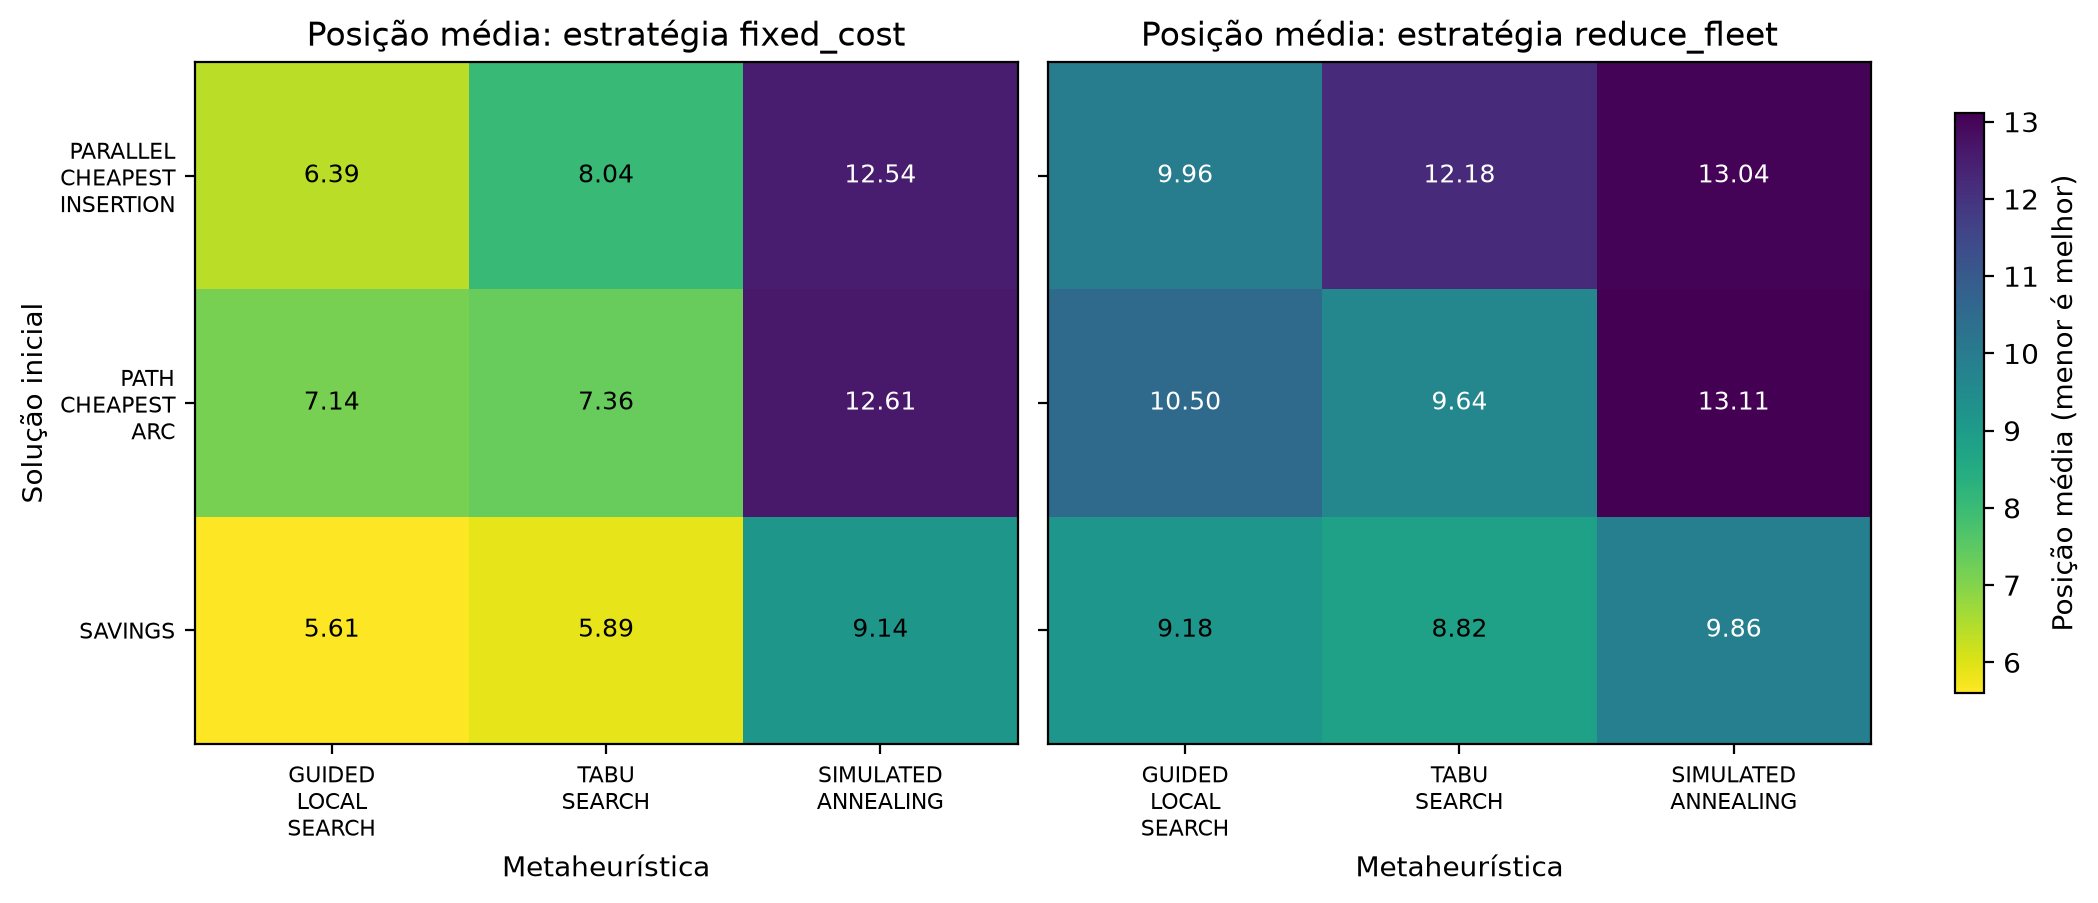

In [3]:
display(eda.localize_columns(analysis.ranking_table(ranking), LANG))

viz_results.plot_rank_heatmap(ranking, LANG)
plt.show()

### Insight

As seis primeiras colocações pertencem todas à estratégia `fixed_cost`: `SAVINGS`/`GUIDED_LOCAL_SEARCH` (5,607), `SAVINGS`/`TABU_SEARCH` (5,893), `PARALLEL_CHEAPEST_INSERTION`/`GUIDED_LOCAL_SEARCH` (6,393), `PATH_CHEAPEST_ARC`/`GUIDED_LOCAL_SEARCH` (7,143), `PATH_CHEAPEST_ARC`/`TABU_SEARCH` (7,357) e `PARALLEL_CHEAPEST_INSERTION`/`TABU_SEARCH` (8,036). Em contraste, `SIMULATED_ANNEALING` ocupa as quatro últimas posições (de 12,536 a 13,107) e aparece em 8º e 11º lugares quando pareado com `SAVINGS` (9,143 e 9,857). No mapa de calor, `SAVINGS` registra a melhor posição média em todas as seis combinações de metaheurística e estratégia de frota.

A vantagem da primeira para a segunda colocada é de 0,286 posição. Apesar de `SAVINGS`/`TABU_SEARCH` apresentar Δ médio de veículos menor (0,786 contra 0,857) e uma igualdade de frota adicional (6 contra 5), seu gap mediano de distância é maior (1,778% contra 1,529%), prevalecendo o critério primário de posição média da regra pré-registrada. Como cada célula teve apenas uma réplica, margens estreitas podem refletir ruído de relógio, além da ressalva estrutural sobre `reduce_fleet` detalhada na seção 8. Em seguida, avalia-se o desempenho absoluto da vencedora por instância.

## 4. Configuração congelada contra o SINTEF

As tabelas abaixo confrontam veículos e distância da configuração congelada com as referências do SINTEF (SINTEF, 2008) em cada instância e por família, relatando Δ de veículos e gap percentual de distância apenas sob frota igual. Incluem-se também colunas de oráculo (melhor das 18), que selecionam *a posteriori* a melhor configuração em cada instância para situar o teto otimista da grade sem constituir regra utilizável.

In [4]:
frozen = analysis.frozen_vs_reference(grid, config)

display(eda.localize_columns(frozen, LANG))
display(eda.localize_columns(analysis.frozen_family_summary(frozen, LANG), LANG))

,Instância,Família,Veículos SINTEF,Distância SINTEF,Veículos,Distância,Δ veículos (vs SINTEF),Gap de distância (%),Melhor das 18: veículos,Melhor das 18: distância,Melhor das 18: Δ veículos
0,C103,C1,10,828.06,10,859.00,0,3.74,10,828.06,0
1,C106,C1,10,828.94,10,828.94,0,0.0,10,828.94,0
2,C203,C2,3,591.17,3,600.21,0,1.53,3,591.17,0
3,C206,C2,3,588.49,3,588.49,0,0.0,3,588.49,0
4,R108,R1,9,960.88,10,970.31,1,-,10,967.80,1
5,R110,R1,10,1118.84,12,1102.83,2,-,12,1102.83,2
6,R111,R1,10,1096.73,11,1107.99,1,-,11,1107.99,1
7,R201,R2,4,1252.37,4,1301.51,0,3.92,4,1283.08,0
8,R202,R2,3,1191.70,4,1114.65,1,-,4,1114.65,1
9,R207,R2,2,890.61,3,851.58,1,-,3,851.58,1


,Família,Nº de instâncias,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Melhor das 18: Δ veículos médio
0,C1,2,0.00,2,1.87,0.00
1,C2,2,0.00,2,0.77,0.00
2,R1,3,1.33,0,-,1.33
3,R2,3,0.67,1,3.92,0.67
4,RC1,2,2.00,0,-,1.50
5,RC2,2,1.00,0,-,0.50
6,Total,14,0.86,5,1.53,0.71


### Insight

A configuração congelada iguala a frota do SINTEF em 5 das 14 instâncias (C103, C106, C203, C206 e R201), emprega 1 veículo adicional em 7 (R108, R111, R202, R207, RC108, RC203 e RC206), 2 em R110 e 3 em RC106, resultando no Δ médio de 0,86 (0,00 em C, 1,33 em R1, 0,67 em R2, 2,00 em RC1 e 1,00 em RC2). Onde as frotas coincidem, os gaps de distância ficam em 0,00% (C106 e C206), 1,53% (C203), 3,74% (C103) e 3,92% (R201), com mediana de 1,53%. Em R110, R202, R207 e RC203 a distância fica abaixo da referência (como 1102,83 contra 1118,84 em R110), porém com frota maior, o que não constitui melhoria no critério hierárquico. O oráculo otimista reduz o Δ médio para 0,71 (baixando RC106 de 14 para 13 e RC203 de 4 para 3), servindo apenas de referência descritiva em réplica única diante de soluções heurísticas do SINTEF. A seção 5 mede quanto a busca local contribui sobre as construções iniciais.

## 5. Efeito da busca local

A tabela compara cada estratégia construtiva isolada (`NONE`) contra o pareamento com a estratégia de frota e a metaheurística congeladas (`fixed_cost` + `GUIDED_LOCAL_SEARCH`), relatando a redução média de Δ de veículos e a contagem de instâncias com redução, empate ou aumento da frota.

In [5]:
display(eda.localize_columns(analysis.local_search_effect(grid, config), LANG))

,Solução inicial,"Δ veículos médio, só construção","Δ veículos médio, com busca local",Veículos economizados (média),Instâncias com menos veículos,Instâncias com frota igual,Instâncias com mais veículos
0,PARALLEL_CHEAPEST_INSERTION,1.86,0.93,0.93,10,4,0
1,PATH_CHEAPEST_ARC,8.36,1.00,7.36,14,0,0
2,SAVINGS,2.79,0.86,1.93,13,1,0


### Insight

Sem busca local, o Δ médio de veículos é de 1,86 (`PARALLEL_CHEAPEST_INSERTION`), 8,36 (`PATH_CHEAPEST_ARC`) e 2,79 (`SAVINGS`). Com `fixed_cost` e `GUIDED_LOCAL_SEARCH`, esses valores recuam para 0,93, 1,00 e 0,86, economizando em média 0,93, 7,36 e 1,93 veículos. A busca local reduziu a frota em 10, 14 e 13 instâncias respectivamente, sem piorar nenhuma das 14. Após 30 s de busca, a diferença entre construções iniciais encolhe para a faixa de 0,86 a 1,00, sugerindo baixa sensibilidade à solução de partida dentro desse orçamento e metaheurística, embora o contraste oponha milissegundos de construção a 30 s de refinamento. A seguir, examinam-se graficamente duas soluções congeladas.

## 6. Rotas da configuração congelada

Os mapas exibem as rotas geradas pela configuração congelada para C103 (clientes agrupados) e R108 (clientes aleatórios) a partir do JSON da grade, diferenciando rotas por cor com o depósito marcado pelo quadrado vermelho e métricas recalculadas no título.

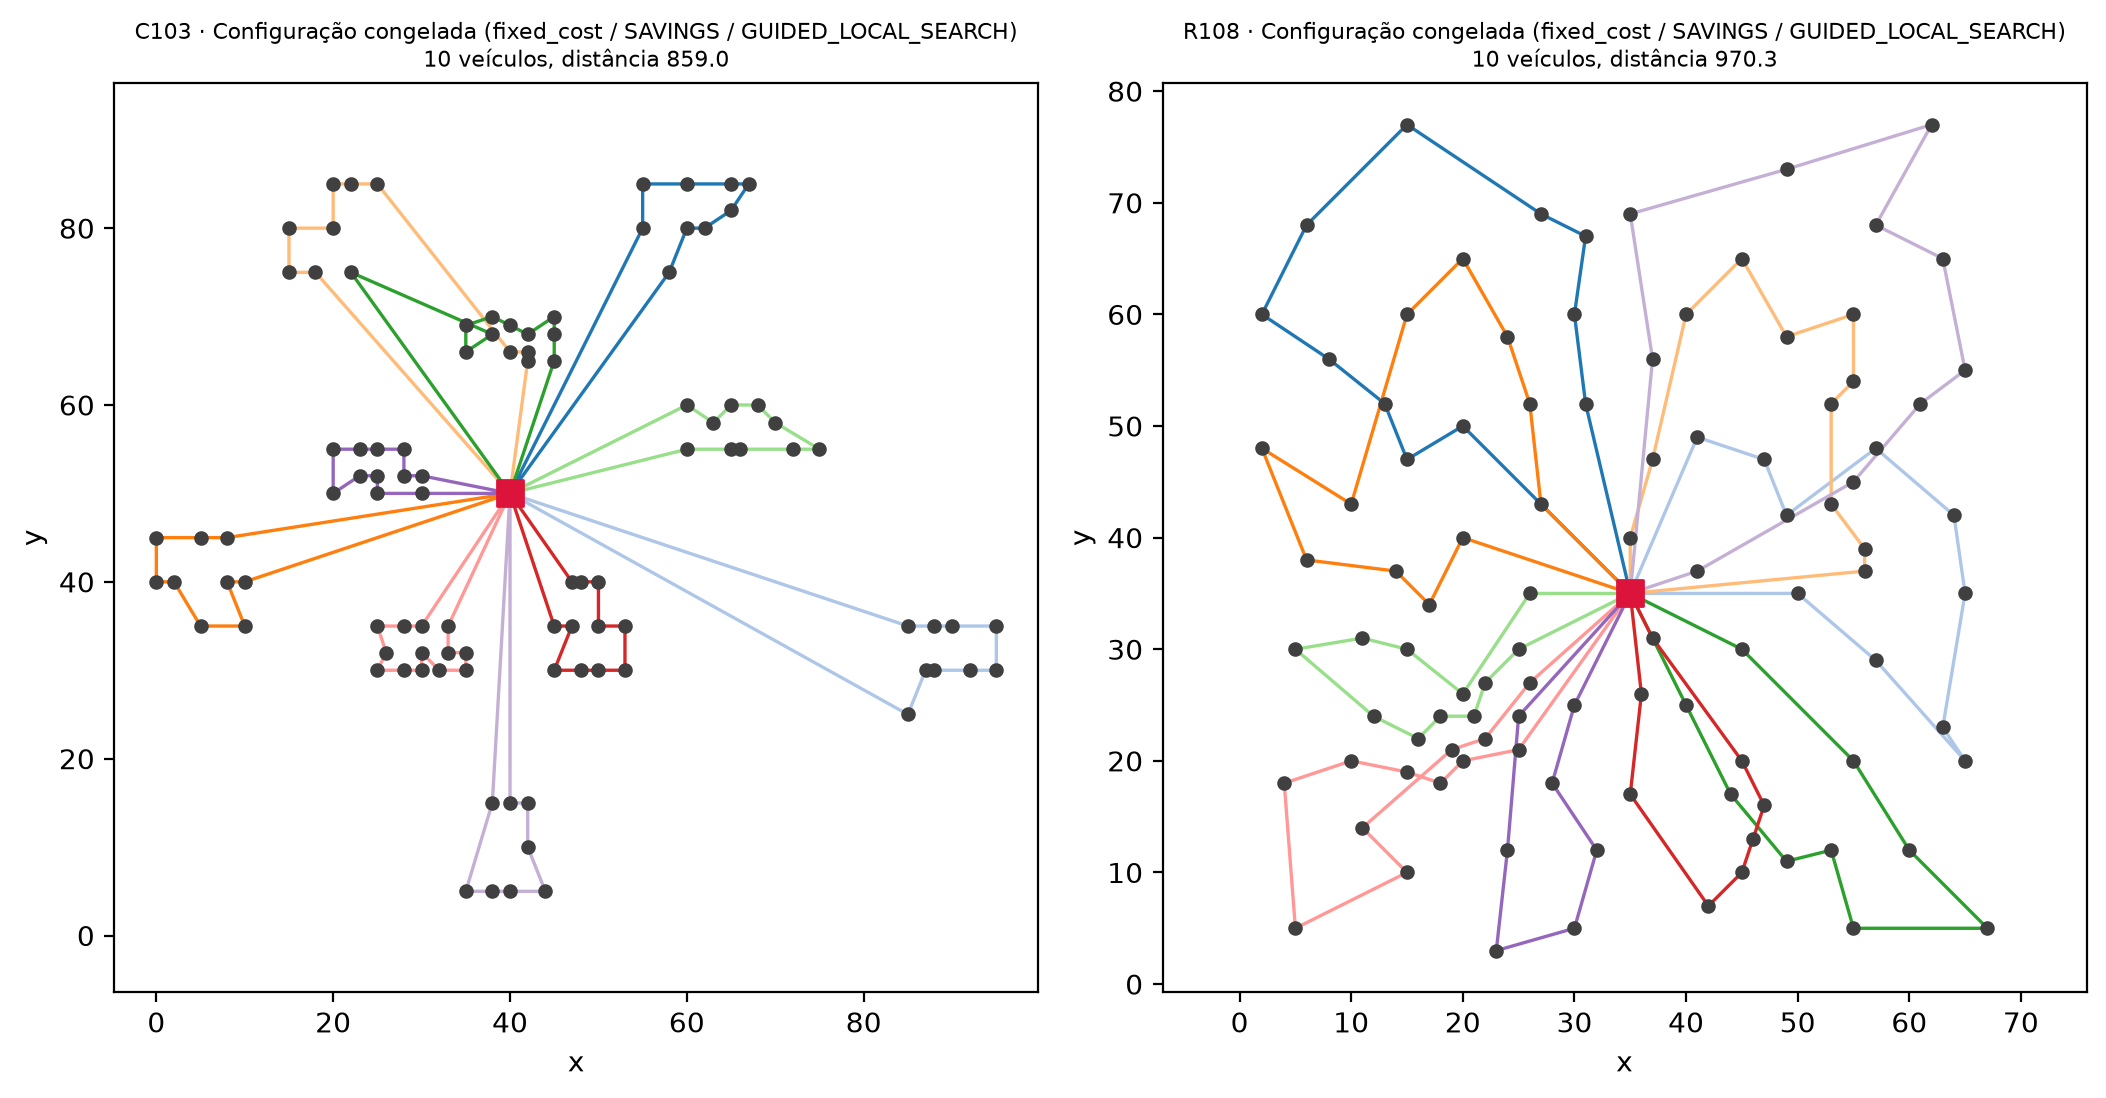

In [6]:
viz_results.plot_route_panels(analysis.frozen_panels(["C103", "R108"], instances, grid, config, LANG), LANG)
plt.show()

### Insight

Em C103 a solução congelada utiliza 10 veículos com distância 859,0 (referência de 10 veículos e 828,06), agrupando cada rota sobre um ou poucos núcleos compactos praticamente sem cruzamentos. Em R108 utiliza 10 veículos e distância 970,3 (contra 9 veículos e 960,88 da referência), formando setores alongados a partir do depósito com certa sobreposição. Trata-se de inspeção qualitativa de dois exemplos, cujas cores distinguem apenas os percursos individuais. Antes de definir o orçamento de avaliação, avalia-se na seção 7 o efeito de tempos maiores de execução.

## 7. Sensibilidade ao orçamento de tempo

Para orientar a escolha do orçamento da avaliação final sem tocar o conjunto de teste, executou-se a configuração congelada (`fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH`) nas 14 instâncias de desenvolvimento sob limites de 10, 30, 60, 120 e 300 s (70 execuções únicas verificadas em precisão dupla, conforme `reports/protocolo-avaliacao.md`). A primeira tabela resume Δ médio de veículos, igualdades de frota, gap mediano nessas igualdades e tempo médio gasto.

In [7]:
time_df = results.load_time_sensitivity(R["time_sensitivity"], split)
curve = analysis.time_curve_table(time_df)

display(eda.localize_columns(analysis.time_curve_table_display(curve), LANG))

,Orçamento (s),Nº de instâncias,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Tempo médio (s)
0,10,14,1.00,5,1.53,10.0
1,30,14,0.86,5,1.53,30.0
2,60,14,0.79,6,1.64,60.0
3,120,14,0.64,7,1.74,120.0
4,300,14,0.64,7,1.16,300.0


### Insight

O Δ médio de veículos recua de 1,00 (10 s) para 0,86 (30 s), 0,79 (60 s) e 0,64 (120 s), estabilizando-se em 0,64 até 300 s. Paralelamente, as instâncias com frota igual à do SINTEF sobem de 5 de 14 (10 s e 30 s) para 6 (60 s) e 7 (120 s e 300 s), consumindo todo o tempo limite em todos os níveis (10,0 a 300,0 s). O gap mediano de distância oscila discretamente (1,53%, 1,53%, 1,64%, 1,74% e 1,16%), porém sobre conjuntos distintos de instâncias com frota igual, impedindo comparação direta entre linhas. Como há apenas uma réplica por orçamento e a parada por relógio admite oscilação de ±1 veículo em R e RC, a curva descreve tendência agregada. A tabela e os gráficos seguintes detalham em quais instâncias a frota se altera.

Os gráficos e a tabela detalham o número de veículos por instância e orçamento contra a referência SINTEF, exibindo o Δ médio em escala logarítmica no painel (a) e as trajetórias individuais das famílias R e RC frente aos alvos tracejados no painel (b).

,Instância,Família,Veículos SINTEF,10 s,30 s,60 s,120 s,300 s
0,C103,C1,10,10,10,10,10,10
1,C106,C1,10,10,10,10,10,10
2,C203,C2,3,3,3,3,3,3
3,C206,C2,3,3,3,3,3,3
4,R108,R1,9,10,10,10,10,10
5,R110,R1,10,12,12,12,12,12
6,R111,R1,10,12,11,11,11,11
7,R201,R2,4,4,4,4,4,4
8,R202,R2,3,4,4,4,4,4
9,R207,R2,2,3,3,3,3,3


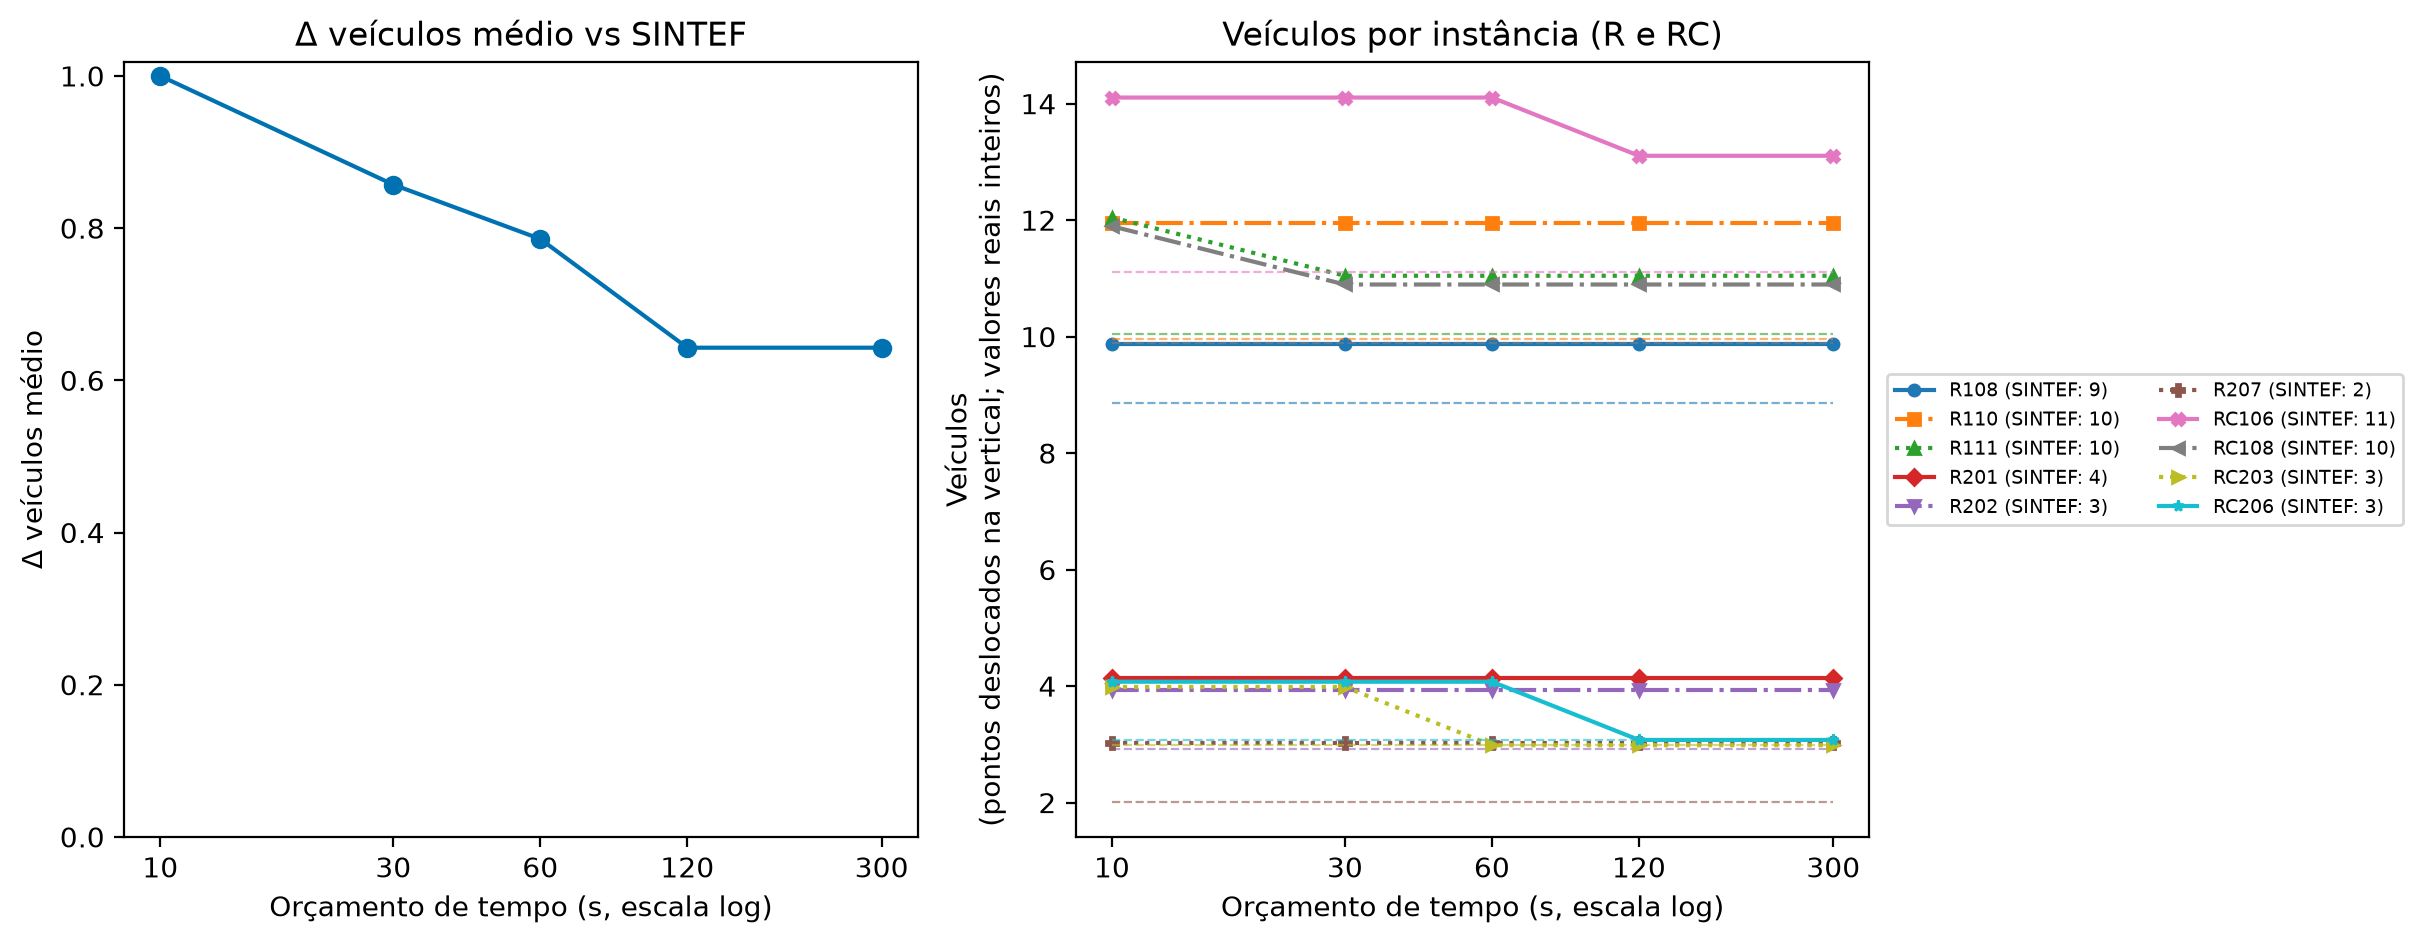

In [8]:
display(eda.localize_columns(analysis.time_curve_by_instance(time_df), LANG))

viz_results.plot_time_curve(time_df, LANG)
plt.show()

### Insight

As instâncias R1 e R2 permanecem estacionárias entre 30 s e 300 s (R108 em 10, R110 em 12, R201 e R202 em 4 e R207 em 3 veículos), tendo apenas R111 caído de 12 para 11 veículos entre 10 s e 30 s. Os ganhos adicionais concentraram-se em RC: RC108 caiu de 12 para 11 entre 10 s e 30 s, RC203 de 4 para 3 em 60 s, e RC106 (14 para 13) e RC206 (4 para 3) em 120 s, enquanto as famílias C mantiveram a frota de referência em todos os tempos. Aos 300 s restam 9 veículos acima do SINTEF distribuídos pelas 7 instâncias R e RC ainda sem igualdade (R108, R110, R111, R202, R207, RC106 e RC108); nas instâncias de frota igual, o gap de R201 caiu de 4,71% (10 s) para 1,16% (300 s) e o de C203 atingiu 0,00% em 300 s, com RC203 e RC206 igualando a frota a gaps de 7,2% e 10,6%. Dada a magnitude de ±1 veículo em execução única, essas variações motivaram o uso de múltiplas réplicas na avaliação final. A seção 8 audita as limitações estruturais da própria grade.

## 8. Limitações auditadas

As duas tabelas extraem diretamente dos registros congelados da grade as limitações operacionais do torneio: a primeira resume falhas imediatas de `reduce_fleet` (campo `attempts`), interrupções precoces de `TABU_SEARCH` antes de 29 s, tempo médio de `GUIDED_LOCAL_SEARCH` e réplicas por célula; a segunda detalha o tempo efetivo de execução de `reduce_fleet` por heurística inicial, contabilizando o mínimo, a mediana, o máximo, as falhas em menos de 1 s após o primeiro passo de 10 s, o uso completo do passo de 5 s e a fração mediana consumida do orçamento.

In [9]:
display(eda.localize_columns(analysis.limitations_table(grid, LANG), LANG))
display(eda.localize_columns(analysis.reduce_fleet_timing(grid), LANG))

,Indicador,Valor
0,Células com a estratégia reduce_fleet,126
1,Células em que a primeira redução de frota não...,126 / 126
2,Tempo médio das células reduce_fleet (s),11.8
3,Células fixed_cost com TABU_SEARCH,42
4,"Das quais, encerradas antes de 29 s",12 / 42
5,Tempo médio de TABU_SEARCH em fixed_cost (s),25.4
6,Tempo médio de GUIDED_LOCAL_SEARCH em fixed_co...,30.0
7,Réplicas por célula (máximo),1


,Solução inicial,Células,Tempo mínimo (s),Tempo mediano (s),Maior tempo de execução (s),Células com tempo < passo inicial + 1 s,Células em que a 2ª tentativa usou o passo inteiro,"Orçamento usado, mediana (%)"
0,PARALLEL_CHEAPEST_INSERTION,42,10.07,10.14,10.28,42,0,33.8
1,PATH_CHEAPEST_ARC,42,6.42,15.01,15.04,2,40,50.0
2,SAVINGS,42,1.08,10.47,12.10,28,0,34.9


### Insight

Em todas as 126 células de `reduce_fleet`, a primeira tentativa de redução (um veículo a menos que a solução inicial) falhou e interrompeu o laço. Os tempos registrados refutam o diagnóstico anterior de que o passo de 5 s teria sido curto: com `PARALLEL_CHEAPEST_INSERTION`, as 42 células levaram entre 10,07 e 10,28 s (mediana 10,14 s), e com `SAVINGS` a mediana foi de 10,47 s (1,08 a 12,10 s), encerrando 28 de 42 células em menos de 1 s após o passo inicial de 10 s. A segunda tentativa falhou quase instantaneamente na fase de construção inicial a frio com frota menor e sem permissão de descarte penalizado, levando o `break` a descartar o restante dos 30 s (uso mediano de 33,8% e 34,9% do orçamento). Na prática, `reduce_fleet` competiu com cerca de 10 s contra 30 s de `fixed_cost`. Somente `PATH_CHEAPEST_ARC` consumiu todo o passo de 5 s (mediana 15,01 s em 40 de 42 células), caso em que a restrição de tempo não pode ser descartada. O caso atípico de 1,08 s (C106, `SAVINGS`, `TABU_SEARCH`) combinou término precoce da primeira resolução (como visto também em `fixed_cost` em 0,95 s e em 12 das 42 células de `TABU_SEARCH`, com média de 25,4 s contra 30,0 s do GLS) com falha imediata da segunda tentativa.

Consequentemente, a comparação original entre `fixed_cost` e `reduce_fleet` é inconclusiva e enviesada contra a redução iterativa, exigindo partida a quente com descarte penalizado, correção testada no bloco B3 da seção 9. A réplica única por célula também impede quantificar o ruído de relógio dentro do torneio, reforçando que a regra de posição média valida a escolha formal sem provar superioridade absoluta sobre margens estreitas.

## 9. Diagnósticos v2 (Fase B)

Após a avaliação final, uma auditoria externa levantou hipóteses sobre falhas do solver (`reports/plano-sanidade-auditoria.md`). Para investigá-las sem comprometer o conjunto de avaliação, registrou-se previamente o protocolo da v2 (`reports/protocolo-v2.md`) exclusivamente sobre as 14 instâncias de desenvolvimento, usando como base a configuração v1 com 120 s, 3 réplicas por célula e 8 processos em máquina ociosa. Cada instância é representada pela réplica mediana lexicográfica (2ª de 3 na ordem factibilidade, veículos e distância), e os níveis competem pela mesma regra de posição média do torneio, com resultados congelados em `outputs/frozen/v2/`. Os blocos B1 a B4 avaliam escala inteira, custo fixo, estratégia de frota e contenção de processos, enquanto o B5 (partida a quente na camada B) integra o notebook 06.

A tabela abaixo audita a cobertura dos quatro blocos (células, instâncias, factibilidade, processos e tempo médio) e resume as decisões registradas em `decision.json`.

In [10]:
blocks = {name: results.load_v2_block(R[f"v2_{name}"], split) for name in ("B1", "B2", "B3", "B4")}
decisions = {name: results.load_v2_decision(R[f"v2_{name}_decision"], split) for name in ("B1", "B2", "B3")}

display(eda.localize_columns(v2_view.block_coverage(blocks, LANG), LANG))
display(eda.localize_columns(v2_view.decision_table(decisions, LANG), LANG))

,Bloco,Células,Nº de instâncias,Factíveis,Processos,Tempo médio (s)
0,B1 · escala inteira,84,14,84,8,120.0
1,B2 · custo fixo por veículo,84,14,84,8,120.0
2,B3 · estratégia de frota,42,14,42,8,112.9
3,B4 · carga da máquina (4 processos),42,14,42,4,120.0


,Bloco,"Níveis (posição média, melhor primeiro)",Nível escolhido,Regra que decidiu
0,B1 · escala inteira,escala 10000: 1.32 · escala 100: 1.68,escala 10000,posição média
1,B2 · custo fixo por veículo,k = 10: 1.89 · k = 100: 1.96 · k = 1: 2.14,k = 10,posição média
2,B3 · estratégia de frota,fixed_cost: 1.32 · reduce_fleet_v2: 1.68,fixed_cost,não é estritamente melhor


### Insight

Os quatro blocos foram executados integralmente nas 14 instâncias de desenvolvimento com 100% de factibilidade em precisão dupla: 84 células em B1, 84 em B2, 42 em B3 e 42 em B4. O tempo médio atingiu o teto de 120,0 s em B1, B2 e B4, ficando em 112,9 s em B3 por término antecipado de tentativas. Pela regra pré-registrada, B1 selecionou a escala 10 000 (posição média 1,32 contra 1,68 da escala 100), B2 manteve k = 10 (1,89 contra 1,96 de k = 100 e 2,14 de k = 1) e B3 manteve `fixed_cost` (1,32 contra 1,68 de `reduce_fleet` v2, que não atingiu superioridade estrita). Como posições médias sobre 14 instâncias e 3 réplicas comportam variabilidade de relógio, as tabelas detalhadas de cada bloco examinam os efeitos individuais.

### B1: escala inteira

Para verificar se a escala inteira 100 com arredondamento para cima poda rotas válidas e se a ampliação para 10 000 recupera veículos, as tabelas a seguir mostram o ranking dos dois níveis, os resultados da réplica representativa por instância diante do SINTEF, os casos com mudança de frota ou variação de distância de ao menos 1%, o agregado comparativo e o comportamento das réplicas de R110.

In [11]:
rows_b1, level_b1 = v2_view.compared_rows("B1", blocks)

display(eda.localize_columns(v2_view.ranking_display(results.load_ranking(R["v2_B1_ranking"]), level_b1, LANG), LANG))
display(eda.localize_columns(v2_view.level_by_instance(rows_b1, level_b1, LANG), LANG))
display(eda.localize_columns(v2_view.pairwise_instances(rows_b1, level_b1, 100, 10000, LANG), LANG))
display(eda.localize_columns(v2_view.level_comparison(rows_b1, level_b1, 100, LANG), LANG))
display(eda.localize_columns(v2_view.replicates_table(rows_b1, "R110", level_b1, LANG), LANG))

,Posição,Escala inteira,Posição média,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Tempo médio (s)
0,1,escala 10000,1.321,0.571,7,1.216,120.0
1,2,escala 100,1.679,0.643,7,1.529,120.0


,Instância,Veículos SINTEF,Veículos (escala 100),Distância (escala 100),Veículos (escala 10000),Distância (escala 10000)
0,C103,10,10,859.0,10,858.1
1,C106,10,10,828.9,10,828.9
2,C203,3,3,600.2,3,594.8
3,C206,3,3,588.5,3,588.5
4,R108,9,10,970.3,10,972.6
5,R110,10,12,1102.8,11,1113.9
6,R111,10,11,1070.3,11,1075.6
7,R201,4,4,1267.6,4,1267.6
8,R202,3,4,1114.6,4,1096.2
9,R207,2,3,830.5,3,823.9


,Instância,Veículos SINTEF,Veículos (base),Veículos (comparado),Distância (base),Distância (comparado),Variação da distância (%)
0,R110,10,12,11,1102.8,1113.9,NaN
1,R202,3,4,4,1114.6,1096.2,-1.7
2,RC203,3,3,3,1125.2,1101.8,-2.1
3,RC206,3,3,3,1268.2,1225.2,-3.4


,Nível,Nº de instâncias,Instâncias com menos veículos,Instâncias com mais veículos,Instâncias com frota igual,"Variação da distância, média (%)","Variação da distância, mediana (%)"
0,escala 10000 / escala 100,14,1,0,13,-0.62,-0.1


,Nível,Veículos por réplica,Veículos,Veículos SINTEF
0,escala 100,12 · 12 · 12,12,10
1,escala 10000,11 · 11 · 11,11,10


### Insight

A escala 10 000 obteve posição média de 1,32 contra 1,68 da escala 100, reduzindo o Δ médio contra o SINTEF de 0,64 para 0,57, mantendo 7 igualdades de frota e reduzindo o gap mediano de distância de 1,53% para 1,22%. O ganho de frota concentrou-se em R110, que recuou de 12 para 11 veículos nas 3 réplicas (aproximando-se da referência 10), confirmando na prática o achado da auditoria sobre o bloqueio causado pela escala 100. Nas demais 13 instâncias a frota não mudou, com variação média de distância de −0,62% (mediana −0,10%) e encurtamentos pontuais em R202 (−1,7%), RC203 (−2,1%) e RC206 (−3,4%), compatíveis com a variação observada entre execuções. Pela regra pré-registrada, a escala 10 000 venceu diretamente na posição média e seguiu para o bloco B2.

### B2: custo fixo por veículo

Para testar a hipótese de que um custo fixo muito alto distorceria a busca local guiada (`GUIDED_LOCAL_SEARCH`) e travaria a redução de frota, compararam-se três magnitudes relativas k ∈ {1, 10, 100} sobre a escala 10 000 (reaproveitando k = 10 do bloco B1). As tabelas exibem o ranking, os valores por instância e a comparação de k = 1 e k = 100 frente a k = 10.

In [12]:
rows_b2, level_b2 = v2_view.compared_rows("B2", blocks)

display(eda.localize_columns(v2_view.ranking_display(results.load_ranking(R["v2_B2_ranking"]), level_b2, LANG), LANG))
display(eda.localize_columns(v2_view.level_by_instance(rows_b2, level_b2, LANG), LANG))
display(eda.localize_columns(v2_view.level_comparison(rows_b2, level_b2, 10.0, LANG), LANG))

,Posição,Custo fixo relativo (k),Posição média,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Tempo médio (s)
0,1,k = 10,1.893,0.571,7,1.216,120.0
1,2,k = 100,1.964,0.571,7,1.216,120.0
2,3,k = 1,2.143,0.571,7,1.529,120.0


,Instância,Veículos SINTEF,Veículos (k = 1),Distância (k = 1),Veículos (k = 10),Distância (k = 10),Veículos (k = 100),Distância (k = 100)
0,C103,10,10,858.1,10,858.1,10,858.1
1,C106,10,10,828.9,10,828.9,10,828.9
2,C203,3,3,600.2,3,594.8,3,594.8
3,C206,3,3,588.5,3,588.5,3,588.5
4,R108,9,10,972.6,10,972.6,10,972.6
5,R110,10,11,1113.9,11,1113.9,11,1113.9
6,R111,10,11,1081.2,11,1075.6,11,1078.2
7,R201,4,4,1267.6,4,1267.6,4,1267.6
8,R202,3,4,1096.2,4,1096.2,4,1096.2
9,R207,2,3,823.9,3,823.9,3,823.9


,Nível,Nº de instâncias,Instâncias com menos veículos,Instâncias com mais veículos,Instâncias com frota igual,"Variação da distância, média (%)","Variação da distância, mediana (%)"
0,k = 1 / k = 10,14,0,0,14,0.10,0.0
1,k = 100 / k = 10,14,0,0,14,0.02,0.0


### Insight

Os três níveis de k produziram exatamente a mesma frota em todas as 14 instâncias (zero ganhos ou perdas de veículos em k = 1 e k = 100 diante de k = 10). As variações médias de distância foram mínimas (+0,10% com k = 1 e +0,02% com k = 100, mediana 0,0%), com k = 10 mantendo a melhor posição média (1,89 contra 1,96 de k = 100 e 2,14 de k = 1) e k = 1 degradando o gap mediano para 1,53% contra 1,22%. Os dados refutam a hipótese de que um custo fixo elevado impedisse a redução de frota nesta grade, ainda que a diferença de 0,07 entre k = 10 e k = 100 seja pequena e o efeito isolado sobre a trajetória da busca não tenha sido inspecionado. Segue-se ao teste da estratégia corrigida de redução de frota.

### B3: estratégia de frota

O bloco B3 confronta `fixed_cost` com a versão corrigida `reduce_fleet` v2 (partida a quente a partir do melhor plano, esvaziamento da menor rota e descarte penalizado apenas durante a etapa de redução, dentro do orçamento total de 120 s), que precisa vencer estritamente na posição média para substituir a estratégia original.

In [13]:
rows_b3, level_b3 = v2_view.compared_rows("B3", blocks)

display(eda.localize_columns(v2_view.ranking_display(results.load_ranking(R["v2_B3_ranking"]), level_b3, LANG), LANG))
display(eda.localize_columns(v2_view.level_by_instance(rows_b3, level_b3, LANG), LANG))
display(eda.localize_columns(v2_view.level_comparison(rows_b3, level_b3, "fixed_cost", LANG), LANG))
display(eda.localize_columns(v2_view.pairwise_instances(rows_b3, level_b3, "fixed_cost", "reduce_fleet_v2", LANG), LANG))

,Posição,Estratégia de frota,Posição média,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Tempo médio (s)
0,1,fixed_cost,1.321,0.571,7,1.216,120.0
1,2,reduce_fleet_v2,1.679,0.500,8,1.852,112.9


,Instância,Veículos SINTEF,Veículos (fixed_cost),Distância (fixed_cost),Veículos (reduce_fleet_v2),Distância (reduce_fleet_v2)
0,C103,10,10,858.1,10,858.1
1,C106,10,10,828.9,10,828.9
2,C203,3,3,594.8,3,600.2
3,C206,3,3,588.5,3,588.5
4,R108,9,10,972.6,10,974.9
5,R110,10,11,1113.9,11,1113.9
6,R111,10,11,1075.6,11,1108.0
7,R201,4,4,1267.6,4,1274.2
8,R202,3,4,1096.2,3,1215.1
9,R207,2,3,823.9,3,860.0


,Nível,Nº de instâncias,Instâncias com menos veículos,Instâncias com mais veículos,Instâncias com frota igual,"Variação da distância, média (%)","Variação da distância, mediana (%)"
0,reduce_fleet_v2 / fixed_cost,14,1,0,13,1.82,0.24


,Instância,Veículos SINTEF,Veículos (base),Veículos (comparado),Distância (base),Distância (comparado),Variação da distância (%)
0,R111,10,11,11,1075.6,1108.0,3.0
1,R202,3,4,3,1096.2,1215.1,NaN
2,R207,2,3,3,823.9,860.0,4.4
3,RC203,3,3,3,1101.8,1236.3,12.2
4,RC206,3,3,3,1225.2,1259.4,2.8


### Insight

`fixed_cost` alcançou posição média 1,32 contra 1,68 de `reduce_fleet` v2 (Δ médio de 0,57 contra 0,50, frota igual em 7 contra 8 instâncias, gap mediano de 1,22% contra 1,85% e tempo médio de 120,0 s contra 112,9 s). A redução iterativa igualou o SINTEF em R202 (4 para 3 veículos), mantendo a mesma frota nas outras 13 instâncias, porém piorou a distância média em 1,82% (mediana 0,24%) sob frota igual, com elevações de 12,2% em RC203, 4,4% em R207, 3,0% em R111 e 2,8% em RC206, efeito compatível com a perda de orçamento gasto em tentativas malsucedidas de esvaziamento. Como não houve ganho na posição média, `fixed_cost` permanece na configuração v2, mantendo ambas as estratégias de +1 a +2 veículos acima do SINTEF em R1 e RC1. O bloco B4 examina o impacto da concorrência entre processos.

### B4: carga da máquina

Para verificar se a execução simultânea de 8 processos induz limitação térmica capaz de alterar a frota ou a distância sob parada por relógio, executou-se a configuração selecionada (`fixed_cost`, escala 10 000, k = 10, 120 s) com 4 processos e comparou-se o resultado célula a célula contra os 8 processos de B1.

In [14]:
display(eda.localize_columns(v2_view.workers_by_instance(blocks["B4"], blocks["B1"], LANG), LANG))

,Instância,Células,Células com frota diferente,Células com distância diferente,"Distância, 8 processos","Distância, 4 processos",Variação da distância (%)
0,C103,3,0,0,858.1,858.1,0.00
1,C106,3,0,0,828.9,828.9,0.00
2,C203,3,0,3,594.8,591.2,-0.62
3,C206,3,0,0,588.5,588.5,0.00
4,R108,3,0,0,972.6,972.6,0.00
5,R110,3,0,0,1113.9,1113.9,0.00
6,R111,3,0,3,1075.6,1078.2,0.24
7,R201,3,0,0,1267.6,1267.6,0.00
8,R202,3,0,0,1096.2,1096.2,0.00
9,R207,3,0,0,823.9,823.9,0.00


### Insight

A frota permaneceu idêntica em todas as 42 células (14 instâncias vezes 3 réplicas) com 4 ou 8 processos. A distância divergiu em 9 células concentradas em três instâncias (C203, R111 e RC106), oscilando nos dois sentidos na réplica representativa: −0,62% em C203 (591,2 contra 594,8), +0,24% em R111 e +0,99% em RC106. Como essas oscilações permanecem dentro da própria variabilidade entre execuções e não alteram nenhum tamanho de frota, manteve-se o padrão de 8 processos na configuração v2 (que difere da v1 pela escala 10 000 e pelo custo fixo relativo k = 10 equivalente a cerca de 50% a 66% do valor absoluto da v1, avaliada pós-hoc no notebook 05).

## 10. Síntese e próximos passos

Sob regra pré-registrada aplicada exclusivamente às 14 instâncias de desenvolvimento, o torneio selecionou `fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH` (posição média 5,607 de 18, Δ médio de 0,86 veículo e 5 igualdades de frota frente ao SINTEF). O refinamento por busca local mostrou-se decisivo ao reduzir o Δ médio das três heurísticas iniciais de 1,86–8,36 para a faixa de 0,86–1,00, deixando `SIMULATED_ANNEALING` nas últimas posições e apresentando margem estreita sobre `TABU_SEARCH` em réplica única.

A estratégia original `reduce_fleet` falhou na construção a frio da primeira redução em todas as 126 células, consumindo cerca de 10,1 a 15,0 s e descartando o orçamento restante, o que tornou o torneio inicial inconclusivo contra ela. Na auditoria da Fase B (seção 9), o bloco B3 retestou `reduce_fleet` v2 com partida a quente e descarte penalizado em 120 s: embora tenha igualado R202 (4 para 3 veículos), perdeu na posição média (1,68 contra 1,32) por piora de distância e manteve `fixed_cost`. Já a sensibilidade temporal (seção 7) registrou redução gradual do Δ médio até 120 s (1,00 em 10 s, 0,86 em 30 s, 0,79 em 60 s e 0,64 em 120 s e 300 s, com ganhos concentrados em RC), informando a adoção de 120 s e 5 réplicas por instância na avaliação final para lidar com a variabilidade de ±1 veículo por relógio em R e RC.

Os diagnósticos da Fase B originaram a configuração v2 (escala inteira 10 000 e custo fixo relativo k = 10, que corresponde a ~50–66% do custo fixo da v1 e elevou R110 de 12 para 11 veículos em B1, sem efeito de frota nos níveis de k em B2 nem mudança de frota com 4 processos em B4). A v1 permanece como resultado principal da avaliação final nas 42 instâncias inéditas (notebook 05), onde Δ de veículos e gap de distância são reportados separadamente frente às melhores soluções conhecidas do SINTEF, figurando a v2 pós-hoc lado a lado sem substituí-la.

## Referências

- Barr, R. S., Golden, B. L., Kelly, J. P., Resende, M. G. C., & Stewart, W. R. (1995). Designing and reporting on computational experiments with heuristic methods. *Journal of Heuristics, 1*(1), 9–32.
- Bräysy, O., & Gendreau, M. (2005b). Vehicle routing problem with time windows, Part II: Metaheuristics. *Transportation Science, 39*(1), 119–139.
- Clarke, G., & Wright, J. W. (1964). Scheduling of vehicles from a central depot to a number of delivery points. *Operations Research, 12*(4), 568–581.
- Glover, F. (1986). Future paths for integer programming and links to artificial intelligence. *Computers & Operations Research, 13*(5), 533–549.
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15.
- Kirkpatrick, S., Gelatt, C. D., & Vecchi, M. P. (1983). Optimization by simulated annealing. *Science, 220*(4598), 671–680.
- Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Voudouris, C., & Tsang, E. (1999). Guided local search and its application to the traveling salesman problem. *European Journal of Operational Research, 113*(2), 469–499.